# 📸 Aesthetic Scene & Photography Style Detection
### Grid-Based Composition Approach — Unsplash Research Dataset Lite

> **Goal:** Detect minimalist vs non-minimalist photography styles using tabular ML with spatial-aware, grid-based composition features.

**Pipeline:**
```
CSV Data → Image Download → Feature Extraction (Global + Grid + Composition) → EDA → Clustering → Evaluation → Model Save
```

In [ ]:
## Unsplash Lite Dataset : https://github.com/unsplash/datasets?tab=readme-ov-file

---
## ⚙️ 0. Environment Setup & Dependencies

In [1]:
# Install required packages (run once)
import subprocess, sys

packages = [
    'opencv-python-headless',
    'scikit-image',
    'scikit-learn',
    'matplotlib',
    'seaborn',
    'pandas',
    'numpy',
    'Pillow',
    'requests',
    'tqdm',
    'joblib',
    'umap-learn',
    'kneed',
]

for pkg in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

print('✅ All packages installed.')


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip



✅ All packages installed.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [2]:
# ── Core imports ──────────────────────────────────────────────────────────────
import os, json, warnings, time, hashlib
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

import cv2
from PIL import Image
import requests
from tqdm.notebook import tqdm

from skimage.feature import local_binary_pattern
from skimage.filters import laplace
from skimage.color import rgb2hsv, rgb2gray

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.manifold import TSNE

import joblib

try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False

try:
    from kneed import KneeLocator
    KNEED_AVAILABLE = True
except ImportError:
    KNEED_AVAILABLE = False

warnings.filterwarnings('ignore')
np.random.seed(42)

# ── Plotting style ─────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'DejaVu Sans',
})
sns.set_palette('husl')

print('✅ Imports successful.')
print(f'   UMAP available: {UMAP_AVAILABLE}')
print(f'   KneeLocator available: {KNEED_AVAILABLE}')

✅ Imports successful.
   UMAP available: True
   KneeLocator available: True


In [3]:
# ── Project directories ────────────────────────────────────────────────────────
BASE_DIR      = Path('grid_project_2')
DATA_DIR      = BASE_DIR / 'data' / 'raw'
IMAGE_DIR     = BASE_DIR / 'data' / 'images'
FEATURE_DIR   = BASE_DIR / 'data' / 'features'
MODEL_DIR     = BASE_DIR / 'models'
REPORT_DIR    = BASE_DIR / 'reports'

for d in [DATA_DIR, IMAGE_DIR, FEATURE_DIR, MODEL_DIR, REPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ── Config ─────────────────────────────────────────────────────────────────────
IMG_SIZE         = (256, 256)   # resize target
GRID_SIZE        = 3            # 3×3 Rule of Thirds
N_WORKERS        = 8            # parallel download threads
DOWNLOAD_TIMEOUT = 15           # seconds per image
LOW_EDGE_THRESH  = 0.05         # empty grid threshold
FEATURE_CACHE    = FEATURE_DIR / 'features.parquet'

print('✅ Project structure ready.')
print(f'   Base: {BASE_DIR.resolve()}')

✅ Project structure ready.
   Base: /Users/rafiabhista/Documents/code/apple/c1_tabular/grid_project_2


---
## 📂 1. Data Loading & Preparation

> Place your Unsplash Research Dataset Lite CSVs inside `project/data/raw/`
> - `photos.tsv` (tab-separated)
> - `keywords.tsv`
> - `colors.tsv`
> - `collections.tsv`
> - `conversions.tsv`

In [4]:
def load_unsplash_csv(filename: str, **kwargs) -> pd.DataFrame:
    """Load Unsplash dataset file — handles both .csv and .tsv variants."""
    candidates = [
        DATA_DIR / filename,
        DATA_DIR / filename.replace('.tsv', '.csv'),
        DATA_DIR / filename.replace('.csv', '.tsv'),
        Path(filename),           # absolute path fallback
    ]
    for path in candidates:
        if path.exists():
            sep = '\t' if str(path).endswith('.tsv') else ','
            df = pd.read_csv(path, sep=sep, low_memory=False, **kwargs)
            print(f'  ✅ Loaded {path.name:30s} → {df.shape[0]:,} rows × {df.shape[1]} cols')
            return df
    raise FileNotFoundError(
        f'Cannot find {filename}. Place it in: {DATA_DIR.resolve()}'
    )

print('Loading Unsplash dataset tables …')
photos      = load_unsplash_csv('photos.tsv')
keywords    = load_unsplash_csv('keywords.tsv')
colors      = load_unsplash_csv('colors.tsv')
collections = load_unsplash_csv('collections.tsv')
conversions = load_unsplash_csv('conversions.tsv')

Loading Unsplash dataset tables …
  ✅ Loaded photos.tsv                     → 25,000 rows × 31 cols
  ✅ Loaded keywords.tsv                   → 755,782 rows × 6 cols
  ✅ Loaded colors.tsv                     → 244,953 rows × 8 cols
  ✅ Loaded collections.tsv                → 2,144,835 rows × 5 cols
  ✅ Loaded conversions.tsv                → 6,246,063 rows × 6 cols


In [5]:
# ── Inspect photos table ───────────────────────────────────────────────────────
print('=== PHOTOS TABLE COLUMNS ===')
print(photos.columns.tolist())
print()
photos.head(3)

=== PHOTOS TABLE COLUMNS ===
['photo_id', 'photo_url', 'photo_image_url', 'photo_submitted_at', 'photo_featured', 'photo_width', 'photo_height', 'photo_aspect_ratio', 'photo_description', 'photographer_username', 'photographer_first_name', 'photographer_last_name', 'exif_camera_make', 'exif_camera_model', 'exif_iso', 'exif_aperture_value', 'exif_focal_length', 'exif_exposure_time', 'photo_location_name', 'photo_location_latitude', 'photo_location_longitude', 'photo_location_country', 'photo_location_city', 'stats_views', 'stats_downloads', 'ai_description', 'ai_primary_landmark_name', 'ai_primary_landmark_latitude', 'ai_primary_landmark_longitude', 'ai_primary_landmark_confidence', 'blur_hash']



,photo_id,photo_url,photo_image_url,photo_submitted_at,photo_featured,photo_width,photo_height,photo_aspect_ratio,photo_description,photographer_username,...,photo_location_country,photo_location_city,stats_views,stats_downloads,ai_description,ai_primary_landmark_name,ai_primary_landmark_latitude,ai_primary_landmark_longitude,ai_primary_landmark_confidence,blur_hash
0,oSf8ePoG9NU,https://unsplash.com/photos/oSf8ePoG9NU,https://images.unsplash.com/20/frozen-grass.JPG,2013-12-04 14:58:49,t,4000,2667,1.5,NaN,andrekoch,...,NaN,NaN,4296224,30072,black road in between white and brown grass ac...,NaN,NaN,NaN,NaN,LPBM;~RkM|of~VRkNHof%1RjRkof
1,DlsOa5moK4w,https://unsplash.com/photos/DlsOa5moK4w,https://images.unsplash.com/reserve/dRA4UuMBR2...,2014-07-10 17:19:38,t,5184,3456,1.5,Fresh blueberries,majkmmiklavc,...,NaN,NaN,8731049,26411,selective focus of blueberry plant,NaN,NaN,NaN,NaN,LiJ+M4s=-pj;~qx]RpbXx1ogRkob
2,XBGacbT3vXI,https://unsplash.com/photos/XBGacbT3vXI,https://images.unsplash.com/photo-143633523196...,2015-07-08 05:54:38.486126,t,6000,4000,1.5,NaN,shooshanig,...,NaN,NaN,2224540,19250,photography of calm beach side,NaN,NaN,NaN,NaN,LSL}HBR*a{fP_NWVoej[x^s.j[ay


In [6]:
# ── Identify image URL column ─────────────────────────────────────────────────
# Unsplash Lite uses 'photo_image_url' or 'photo_url'
URL_COL = None
for candidate in ['photo_image_url', 'photo_url', 'urls_raw', 'url']:
    if candidate in photos.columns:
        URL_COL = candidate
        break

ID_COL = 'photo_id' if 'photo_id' in photos.columns else photos.columns[0]

print(f'ID column  : {ID_COL}')
print(f'URL column : {URL_COL}')
print(f'Total photos: {len(photos):,}')

ID column  : photo_id
URL column : photo_image_url
Total photos: 25,000


In [7]:
# ── Clean photos table ─────────────────────────────────────────────────────────
photos = photos.dropna(subset=[ID_COL])
photos[ID_COL] = photos[ID_COL].astype(str).str.strip()

if URL_COL:
    photos = photos.dropna(subset=[URL_COL])
    # Build resized URL: append ?w=256&h=256&fit=crop for Unsplash
    def make_url(base_url: str) -> str:
        base = str(base_url).split('?')[0]
        return f'{base}?w=256&h=256&fit=crop&auto=format'
    photos['download_url'] = photos[URL_COL].apply(make_url)
else:
    print('⚠️  No URL column found — will skip image download.')
    photos['download_url'] = None

print(f'Clean photos after removing nulls: {len(photos):,}')
photos[[ID_COL, 'download_url']].head()

Clean photos after removing nulls: 25,000


,photo_id,download_url
0,oSf8ePoG9NU,https://images.unsplash.com/20/frozen-grass.JP...
1,DlsOa5moK4w,https://images.unsplash.com/reserve/dRA4UuMBR2...
2,XBGacbT3vXI,https://images.unsplash.com/photo-143633523196...
3,FjikPptEbZg,https://images.unsplash.com/flagged/photo-1441...
4,PXdBkNF8rlk,https://images.unsplash.com/photo-144596683821...


In [9]:
# ── Merge supplementary tables onto photos ─────────────────────────────────────
# Aggregate keywords per photo
if 'keyword' in keywords.columns:
    kw_agg = keywords.groupby('photo_id')['keyword'].apply(lambda x: '|'.join(x.dropna())).reset_index()
    kw_agg.columns = ['photo_id', 'keywords_list']
    photos = photos.merge(kw_agg, left_on=ID_COL, right_on='photo_id', how='left')

# Dominant color per photo (first color)
if 'hex' in colors.columns:
    col_first = colors.drop_duplicates('photo_id')[['photo_id', 'hex', 'score']]
    col_first.columns = ['photo_id', 'dominant_hex', 'dominant_pct']
    photos = photos.merge(col_first, left_on=ID_COL, right_on='photo_id', how='left')

# Download count from conversions
if 'conversion_type' in conversions.columns:
    dl = conversions[conversions['conversion_type']=='download'].groupby('photo_id').size().reset_index(name='download_count')
    photos = photos.merge(dl, left_on=ID_COL, right_on='photo_id', how='left')
    photos['download_count'] = photos['download_count'].fillna(0).astype(int)

print(f'Merged dataframe: {photos.shape}')
photos.head(2)

Merged dataframe: (25000, 37)


,photo_id,photo_url,photo_image_url,photo_submitted_at,photo_featured,photo_width,photo_height,photo_aspect_ratio,photo_description,photographer_username,...,ai_primary_landmark_latitude,ai_primary_landmark_longitude,ai_primary_landmark_confidence,blur_hash,download_url,keywords_list_x,keywords_list_y,dominant_hex,dominant_pct,download_count
0,oSf8ePoG9NU,https://unsplash.com/photos/oSf8ePoG9NU,https://images.unsplash.com/20/frozen-grass.JPG,2013-12-04 14:58:49,t,4000,2667,1.5,NaN,andrekoch,...,NaN,NaN,NaN,LPBM;~RkM|of~VRkNHof%1RjRkof,https://images.unsplash.com/20/frozen-grass.JP...,plant|field|ice|frozen|forest|grass|reflection...,plant|field|ice|frozen|forest|grass|reflection...,121312,0.176327,7
1,DlsOa5moK4w,https://unsplash.com/photos/DlsOa5moK4w,https://images.unsplash.com/reserve/dRA4UuMBR2...,2014-07-10 17:19:38,t,5184,3456,1.5,Fresh blueberries,majkmmiklavc,...,NaN,NaN,NaN,LiJ+M4s=-pj;~qx]RpbXx1ogRkob,https://images.unsplash.com/reserve/dRA4UuMBR2...,berry|growth|produce|blueberry|pottery|leaf|bu...,berry|growth|produce|blueberry|pottery|leaf|bu...,1a3248,0.004330,16


---
## 📊 2. Exploratory Data Analysis (EDA)

In [10]:
# ── Basic dataset stats ────────────────────────────────────────────────────────
print('=== DATASET OVERVIEW ===')
print(f'Total photos       : {len(photos):,}')
print(f'Columns            : {photos.shape[1]}')
print(f'Missing URL        : {photos["download_url"].isna().sum():,}')
if 'photo_width' in photos.columns:
    print(f'Avg width          : {photos["photo_width"].median():.0f}px')
    print(f'Avg height         : {photos["photo_height"].median():.0f}px')
if 'download_count' in photos.columns:
    print(f'Median downloads   : {photos["download_count"].median():.0f}')
    print(f'Max downloads      : {photos["download_count"].max():,}')

=== DATASET OVERVIEW ===
Total photos       : 25,000
Columns            : 37
Missing URL        : 0
Avg width          : 4080px
Avg height         : 4000px
Median downloads   : 16
Max downloads      : 57,355


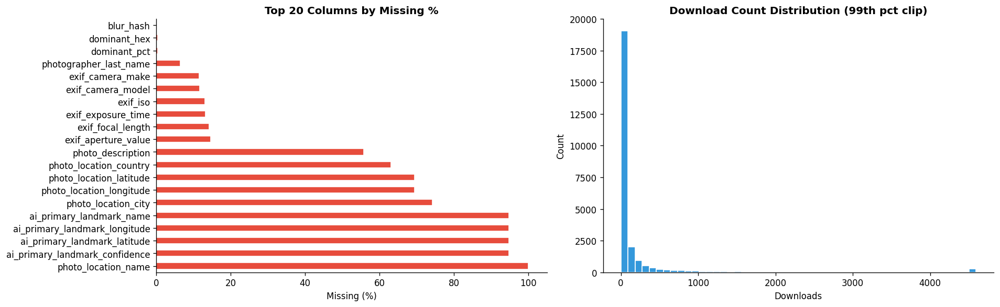

In [11]:
# ── Missing value heatmap ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Missing values
miss_pct = photos.isnull().mean().sort_values(ascending=False).head(20) * 100
miss_pct.plot(kind='barh', ax=axes[0], color='#E74C3C', edgecolor='white')
axes[0].set_title('Top 20 Columns by Missing %', fontweight='bold')
axes[0].set_xlabel('Missing (%)')

# Download distribution (if available)
if 'download_count' in photos.columns and photos['download_count'].sum() > 0:
    dc = photos['download_count'].clip(upper=photos['download_count'].quantile(0.99))
    axes[1].hist(dc, bins=50, color='#3498DB', edgecolor='white')
    axes[1].set_title('Download Count Distribution (99th pct clip)', fontweight='bold')
    axes[1].set_xlabel('Downloads')
    axes[1].set_ylabel('Count')
else:
    axes[1].text(0.5, 0.5, 'Download data not available', ha='center', va='center', transform=axes[1].transAxes)
    axes[1].set_title('Download Distribution', fontweight='bold')

plt.tight_layout()
plt.savefig(REPORT_DIR / 'eda_overview.png', bbox_inches='tight')
plt.show()

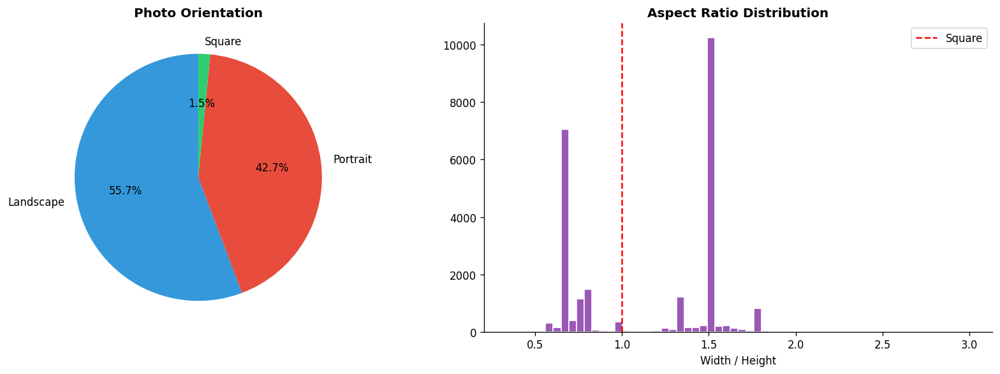

In [12]:
# ── Aspect ratio analysis ──────────────────────────────────────────────────────
if 'photo_width' in photos.columns and 'photo_height' in photos.columns:
    photos['aspect_ratio'] = photos['photo_width'] / photos['photo_height'].replace(0, np.nan)
    photos['orientation'] = photos['aspect_ratio'].apply(
        lambda r: 'Landscape' if r > 1.05 else ('Portrait' if r < 0.95 else 'Square')
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Orientation pie
    ori_counts = photos['orientation'].value_counts()
    axes[0].pie(ori_counts, labels=ori_counts.index, autopct='%1.1f%%',
                colors=['#3498DB', '#E74C3C', '#2ECC71'], startangle=90)
    axes[0].set_title('Photo Orientation', fontweight='bold')

    # Aspect ratio histogram
    ar_clip = photos['aspect_ratio'].clip(0.2, 3.0).dropna()
    axes[1].hist(ar_clip, bins=60, color='#9B59B6', edgecolor='white')
    axes[1].axvline(1.0, color='red', linestyle='--', label='Square')
    axes[1].set_title('Aspect Ratio Distribution', fontweight='bold')
    axes[1].set_xlabel('Width / Height')
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(REPORT_DIR / 'eda_aspect_ratio.png', bbox_inches='tight')
    plt.show()
else:
    print('No width/height columns — skipping aspect ratio EDA.')

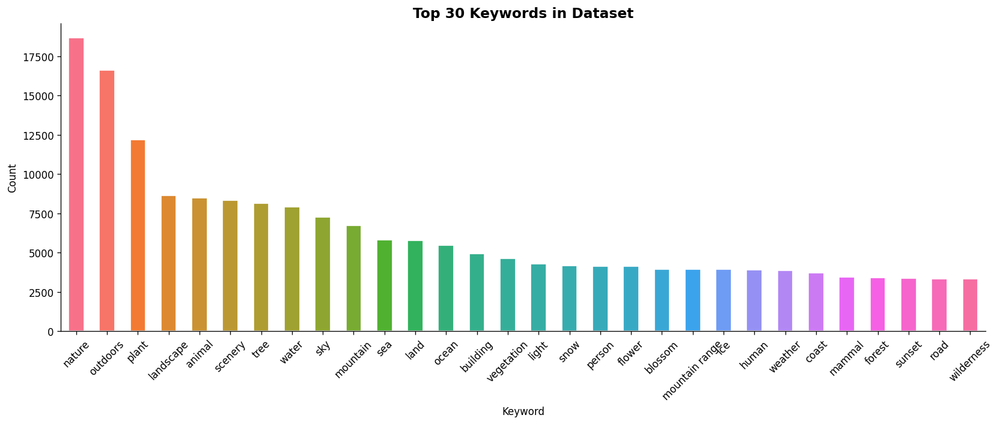

In [13]:
# ── Top keywords ───────────────────────────────────────────────────────────────
if 'keyword' in keywords.columns:
    kw_counts = keywords['keyword'].value_counts().head(30)

    fig, ax = plt.subplots(figsize=(14, 6))
    kw_counts.plot(kind='bar', ax=ax, color=sns.color_palette('husl', 30), edgecolor='white')
    ax.set_title('Top 30 Keywords in Dataset', fontweight='bold', fontsize=14)
    ax.set_xlabel('Keyword')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.savefig(REPORT_DIR / 'eda_keywords.png', bbox_inches='tight')
    plt.show()

---
## 🌐 3. Image Download

Downloads **all** images with multi-threaded parallel requests and a local cache.

In [14]:
def download_image(row) -> dict:
    """Download one image; returns status dict."""
    photo_id  = row[ID_COL]
    url       = row['download_url']
    out_path  = IMAGE_DIR / f'{photo_id}.jpg'

    if out_path.exists() and out_path.stat().st_size > 1000:
        return {'photo_id': photo_id, 'status': 'cached', 'path': str(out_path)}

    try:
        resp = requests.get(url, timeout=DOWNLOAD_TIMEOUT,
                            headers={'User-Agent': 'Mozilla/5.0'})
        resp.raise_for_status()
        with open(out_path, 'wb') as f:
            f.write(resp.content)
        return {'photo_id': photo_id, 'status': 'ok', 'path': str(out_path)}
    except Exception as e:
        return {'photo_id': photo_id, 'status': 'error', 'path': None, 'error': str(e)}

In [15]:
rows = photos[photos['download_url'].notna()].to_dict('records')
print(f'Images to download/verify: {len(rows):,}')

results = []
with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
    futures = {pool.submit(download_image, r): r for r in rows}
    for future in tqdm(as_completed(futures), total=len(futures), desc='Downloading images'):
        results.append(future.result())

dl_df = pd.DataFrame(results)
status_counts = dl_df['status'].value_counts()
print('\n=== Download Summary ===')
print(status_counts.to_string())

# Attach local path back to photos
photos = photos.merge(dl_df[['photo_id', 'path']].rename(columns={'photo_id': ID_COL}),
                      on=ID_COL, how='left')
photos_valid = photos[photos['path'].notna()].copy()
print(f'\nImages available for feature extraction: {len(photos_valid):,}')

Images to download/verify: 25,000



=== Download Summary ===
status
ok       24997
error        3

Images available for feature extraction: 24,997


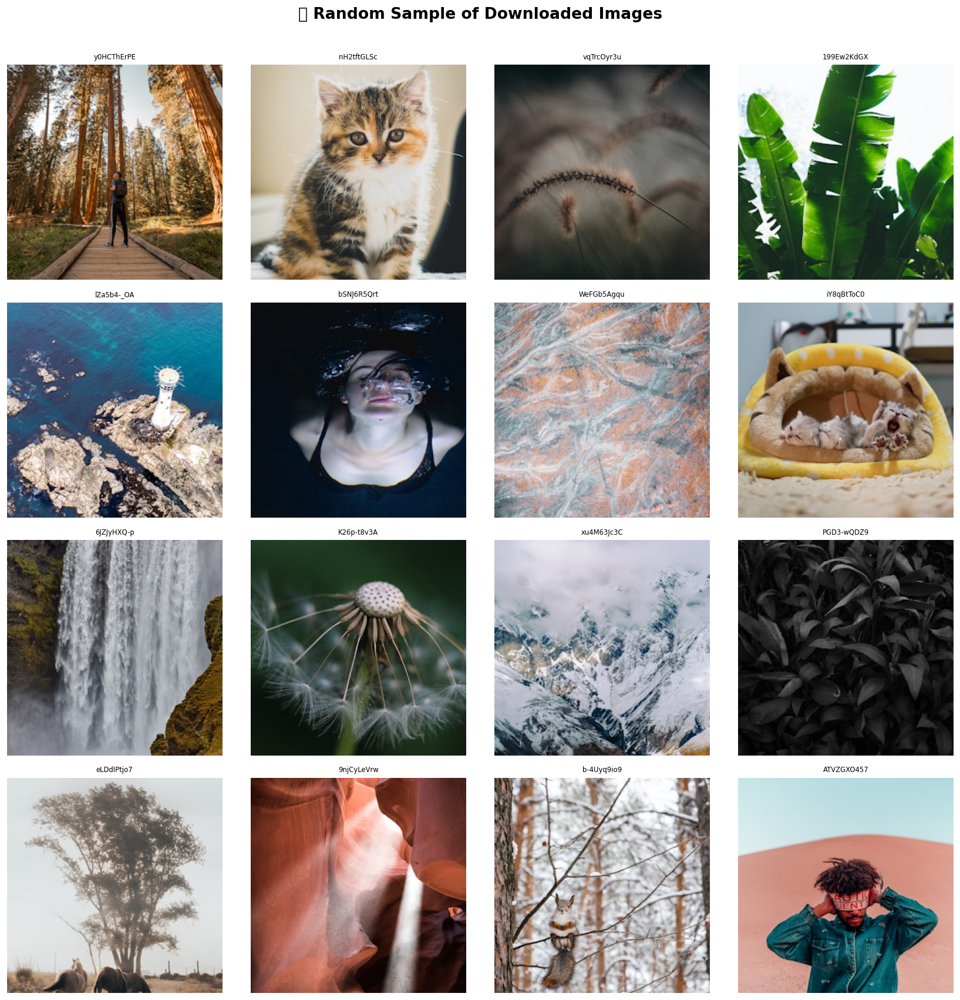

In [16]:
# ── Visual sample of downloaded images ────────────────────────────────────────
sample_paths = photos_valid['path'].dropna().sample(min(16, len(photos_valid)), random_state=42).tolist()

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
fig.suptitle('📷 Random Sample of Downloaded Images', fontsize=16, fontweight='bold', y=1.01)

for ax, path in zip(axes.flatten(), sample_paths):
    try:
        img = Image.open(path).convert('RGB').resize((256, 256))
        ax.imshow(img)
        photo_id = Path(path).stem[:10]
        ax.set_title(photo_id, fontsize=7)
    except Exception:
        ax.text(0.5, 0.5, 'Error', ha='center', va='center')
    ax.axis('off')

plt.tight_layout()
plt.savefig(REPORT_DIR / 'sample_images.png', bbox_inches='tight')
plt.show()

---
## 🔬 4. Feature Extraction

Three layers of features:
1. **Global** — overall appearance
2. **Grid (3×3)** — spatial structure (Rule of Thirds)
3. **Composition** — derived from grid features

In [17]:
# ── Feature extraction functions ───────────────────────────────────────────────

def colorfulness_hasler_susstrunk(img_rgb: np.ndarray) -> float:
    """Hasler & Süsstrunk (2003) colorfulness metric."""
    R, G, B = img_rgb[:,:,0].astype(float), img_rgb[:,:,1].astype(float), img_rgb[:,:,2].astype(float)
    rg = R - G
    yb = 0.5*(R + G) - B
    return float(np.sqrt(rg.std()**2 + yb.std()**2) + 0.3 * np.sqrt(rg.mean()**2 + yb.mean()**2))


def lbp_entropy(gray: np.ndarray) -> float:
    """Local Binary Pattern entropy — texture complexity."""
    lbp = local_binary_pattern(gray, P=8, R=1.0, method='uniform')
    hist, _ = np.histogram(lbp, bins=10, density=True)
    hist = hist[hist > 0]
    return float(-np.sum(hist * np.log2(hist)))


def extract_global_features(img_rgb: np.ndarray) -> dict:
    """Extract global image features."""
    gray  = rgb2gray(img_rgb)
    hsv   = rgb2hsv(img_rgb)

    brightness  = float(gray.mean())
    contrast    = float(gray.std())
    sharpness   = float(laplace(gray).var())
    saturation  = float(hsv[:,:,1].mean())
    colorful    = colorfulness_hasler_susstrunk(img_rgb)
    texture_ent = lbp_entropy(gray)

    # Edge density via Canny
    edges = cv2.Canny((gray * 255).astype(np.uint8), 50, 150)
    edge_density = float(edges.mean() / 255.0)

    # Hue histogram spread
    hue_std = float(hsv[:,:,0].std())

    return {
        'brightness':   brightness,
        'contrast':     contrast,
        'sharpness':    sharpness,
        'edge_density': edge_density,
        'saturation':   saturation,
        'colorfulness': colorful,
        'texture_ent':  texture_ent,
        'hue_std':      hue_std,
    }


def extract_grid_features(img_rgb: np.ndarray, grid: int = GRID_SIZE) -> dict:
    """Extract per-cell features from a grid×grid decomposition."""
    H, W = img_rgb.shape[:2]
    ch   = H // grid
    cw   = W // grid
    gray = rgb2gray(img_rgb)

    feats = {}
    for row in range(grid):
        for col in range(grid):
            idx  = row * grid + col + 1
            cell = gray[row*ch:(row+1)*ch, col*cw:(col+1)*cw]
            cell_rgb = img_rgb[row*ch:(row+1)*ch, col*cw:(col+1)*cw]

            # Edge density
            edges_c = cv2.Canny((cell * 255).astype(np.uint8), 50, 150)
            feats[f'edge_{idx}'] = float(edges_c.mean() / 255.0)

            # Sharpness
            feats[f'sharp_{idx}'] = float(laplace(cell).var())

            # Brightness
            feats[f'bright_{idx}'] = float(cell.mean())

    return feats


def extract_composition_features(grid_feats: dict, grid: int = GRID_SIZE) -> dict:
    """Derive composition-level features from grid features."""
    n_cells = grid * grid
    center  = (grid // 2) * grid + (grid // 2) + 1  # center cell index for 3×3 → 5

    edges  = np.array([grid_feats[f'edge_{i}']  for i in range(1, n_cells+1)])
    sharps = np.array([grid_feats[f'sharp_{i}'] for i in range(1, n_cells+1)])
    brights= np.array([grid_feats[f'bright_{i}']for i in range(1, n_cells+1)])

    # 1. Edge concentration — single dominant subject
    edge_sum = edges.sum() + 1e-8
    edge_max_ratio = float(edges.max() / edge_sum)

    # 2. Spatial distribution — minimalist = high variance (one cluster)
    edge_std = float(edges.std())

    # 3. Empty space ratio — negative space (low-edge cells)
    empty_ratio = float((edges < LOW_EDGE_THRESH).sum() / n_cells)

    # 4. Center dominance
    center_edge = grid_feats[f'edge_{center}']
    others_mean = edges[edges != center_edge].mean() + 1e-8
    center_ratio = float(center_edge / others_mean)

    # 5. Sharpness concentration — where is the focus?
    sharp_max_ratio = float(sharps.max() / (sharps.sum() + 1e-8))
    sharp_std       = float(sharps.std())

    # 6. Rule-of-thirds hotspot — are the PoI on the 4 intersection cells?
    thirds_cells = [2, 4, 6, 8]  # 1-indexed for 3×3
    thirds_edges = np.array([grid_feats[f'edge_{i}'] for i in thirds_cells])
    thirds_ratio = float(thirds_edges.mean() / (edges.mean() + 1e-8))

    # 7. Top-heavy / bottom-heavy
    top_row    = edges[:grid].mean()
    bottom_row = edges[-grid:].mean()
    vertical_balance = float(top_row / (bottom_row + 1e-8))

    # 8. Left-right balance
    left_col   = edges[0::grid].mean()
    right_col  = edges[grid-1::grid].mean()
    horiz_balance = float(left_col / (right_col + 1e-8))

    # 9. Brightness uniformity
    bright_std = float(brights.std())

    return {
        'edge_max_ratio':  edge_max_ratio,
        'edge_std':        edge_std,
        'empty_ratio':     empty_ratio,
        'center_ratio':    center_ratio,
        'sharp_max_ratio': sharp_max_ratio,
        'sharp_std':       sharp_std,
        'thirds_ratio':    thirds_ratio,
        'vertical_balance':vertical_balance,
        'horiz_balance':   horiz_balance,
        'bright_std':      bright_std,
    }


def extract_all_features(image_path: str) -> dict | None:
    """Load image and extract ALL features. Returns None on failure."""
    try:
        img = Image.open(image_path).convert('RGB').resize(IMG_SIZE)
        img_np = np.array(img)

        global_f = extract_global_features(img_np)
        grid_f   = extract_grid_features(img_np)
        comp_f   = extract_composition_features(grid_f)

        return {**global_f, **grid_f, **comp_f}
    except Exception:
        return None


print('✅ Feature extraction functions defined.')
print(f'\nFeature groups:')
print(f'  Global      : 8 features')
print(f'  Grid (3×3)  : {3 * GRID_SIZE * GRID_SIZE} features (edge + sharp + bright × 9 cells)')
print(f'  Composition : 10 features')
print(f'  Total       : ~{8 + 3*9 + 10} features')

✅ Feature extraction functions defined.

Feature groups:
  Global      : 8 features
  Grid (3×3)  : 27 features (edge + sharp + bright × 9 cells)
  Composition : 10 features
  Total       : ~45 features


In [18]:
# ── Quick sanity check on one image ───────────────────────────────────────────
test_path = photos_valid['path'].iloc[0]
test_feats = extract_all_features(test_path)
print(f'Feature count for test image: {len(test_feats)}')
print(pd.Series(test_feats).to_string())

Feature count for test image: 45
brightness           0.325103
contrast             0.241219
sharpness            0.029760
edge_density         0.229904
saturation           0.173792
colorfulness        19.186043
texture_ent          3.462965
hue_std              0.195973
edge_1               0.213426
sharp_1              0.021909
bright_1             0.481233
edge_2               0.204291
sharp_2              0.018842
bright_2             0.512502
edge_3               0.206782
sharp_3              0.016169
bright_3             0.572160
edge_4               0.203322
sharp_4              0.024875
bright_4             0.285708
edge_5               0.207889
sharp_5              0.027830
bright_5             0.287309
edge_6               0.217301
sharp_6              0.031907
bright_6             0.279478
edge_7               0.261592
sharp_7              0.034528
bright_7             0.160780
edge_8               0.284844
sharp_8              0.046503
bright_8             0.181409
edge_9 

In [19]:
# ── Batch feature extraction with caching ─────────────────────────────────────
if FEATURE_CACHE.exists():
    print(f'📦 Loading cached features from {FEATURE_CACHE} …')
    features_df = pd.read_parquet(FEATURE_CACHE)
    print(f'   {len(features_df):,} rows × {features_df.shape[1]} cols')
else:
    print(f'Extracting features for {len(photos_valid):,} images …')
    paths = photos_valid['path'].tolist()
    ids   = photos_valid[ID_COL].tolist()

    all_feats = []
    failed    = 0

    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        futures = {pool.submit(extract_all_features, p): pid
                   for p, pid in zip(paths, ids)}
        for future in tqdm(as_completed(futures), total=len(futures), desc='Extracting features'):
            pid = futures[future]
            res = future.result()
            if res is not None:
                res['photo_id'] = pid
                all_feats.append(res)
            else:
                failed += 1

    features_df = pd.DataFrame(all_feats)
    features_df.to_parquet(FEATURE_CACHE, index=False)
    print(f'\n✅ Extracted: {len(features_df):,} | Failed: {failed}')
    print(f'💾 Saved to {FEATURE_CACHE}')

features_df.head(3)

Extracting features for 24,997 images …


Extracting features:   0%|          | 0/24997 [00:00<?, ?it/s]


✅ Extracted: 24,997 | Failed: 0
💾 Saved to grid_project_2/data/features/features.parquet


,brightness,contrast,sharpness,edge_density,saturation,colorfulness,texture_ent,hue_std,edge_1,sharp_1,...,edge_std,empty_ratio,center_ratio,sharp_max_ratio,sharp_std,thirds_ratio,vertical_balance,horiz_balance,bright_std,photo_id
0,0.623492,0.248044,0.003976,0.108521,0.428038,65.745067,2.810322,0.106078,0.016194,0.000423,...,0.048163,0.111111,1.590010,0.387293,0.004075,1.033203,0.379298,0.695493,0.174699,DlsOa5moK4w
1,0.734458,0.151297,0.006059,0.100388,0.136325,20.540859,3.349539,0.098908,0.000000,0.000090,...,0.073825,0.333333,1.291116,0.213316,0.004374,1.080659,0.000000,0.995671,0.075339,XBGacbT3vXI
2,0.549819,0.249124,0.005188,0.079224,0.478562,51.654927,3.190097,0.038962,0.000000,0.000018,...,0.068042,0.333333,3.264017,0.275258,0.004426,1.073023,0.000000,0.921101,0.172433,PXdBkNF8rlk


In [20]:
# ── Merge features with metadata ───────────────────────────────────────────────
meta_cols = [ID_COL, 'path']
for c in ['photo_width','photo_height','aspect_ratio','orientation',
           'dominant_hex','download_count','keywords_list']:
    if c in photos_valid.columns:
        meta_cols.append(c)

df = photos_valid[meta_cols].merge(
    features_df,
    left_on=ID_COL, right_on='photo_id', how='inner'
)
print(f'Combined df: {df.shape}')

Combined df: (24997, 53)


---
## 📊 5. Feature EDA

In [21]:
# ── Feature columns ────────────────────────────────────────────────────────────
GLOBAL_FEATS = ['brightness','contrast','sharpness','edge_density',
                'saturation','colorfulness','texture_ent','hue_std']
GRID_FEATS   = [f'{t}_{i}' for t in ['edge','sharp','bright'] for i in range(1,10)]
COMP_FEATS   = ['edge_max_ratio','edge_std','empty_ratio','center_ratio',
                'sharp_max_ratio','sharp_std','thirds_ratio',
                'vertical_balance','horiz_balance','bright_std']
ALL_FEATS    = GLOBAL_FEATS + GRID_FEATS + COMP_FEATS

# Make sure all feature cols exist in df
ALL_FEATS = [f for f in ALL_FEATS if f in df.columns]
print(f'Total features used: {len(ALL_FEATS)}')

Total features used: 45


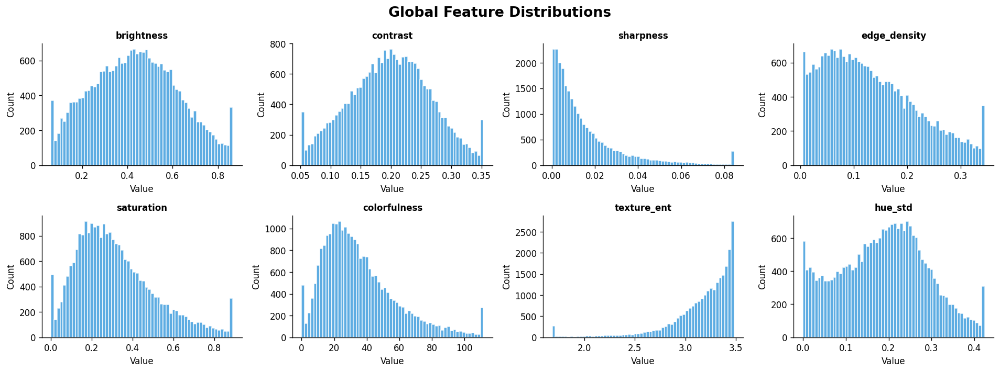

In [22]:
# ── Global feature distributions ──────────────────────────────────────────────
g_feats = [f for f in GLOBAL_FEATS if f in df.columns]
n = len(g_feats)
ncols = 4
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 3))
fig.suptitle('Global Feature Distributions', fontsize=16, fontweight='bold')

for ax, feat in zip(axes.flatten(), g_feats):
    data = df[feat].dropna()
    ax.hist(data.clip(data.quantile(0.01), data.quantile(0.99)),
            bins=60, color='#3498DB', edgecolor='white', alpha=0.8)
    ax.set_title(feat, fontweight='bold', fontsize=10)
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')

for ax in axes.flatten()[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(REPORT_DIR / 'feature_distributions_global.png', bbox_inches='tight')
plt.show()

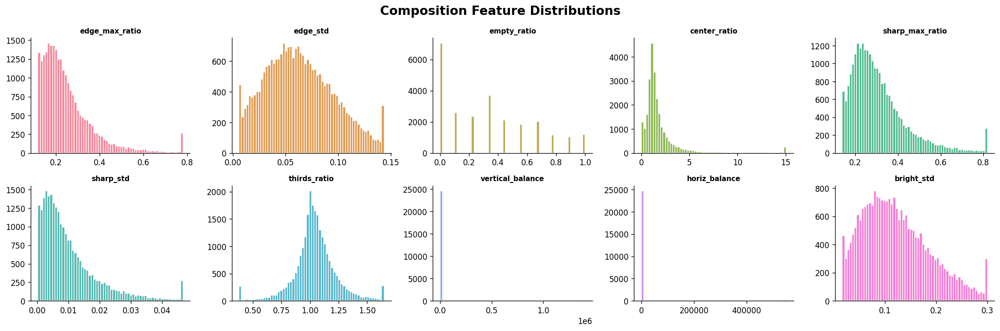

In [23]:
# ── Composition feature distributions ─────────────────────────────────────────
c_feats = [f for f in COMP_FEATS if f in df.columns]
n = len(c_feats)
ncols = 5
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 3))
fig.suptitle('Composition Feature Distributions', fontsize=16, fontweight='bold')

palette = sns.color_palette('husl', n)
for ax, feat, color in zip(axes.flatten(), c_feats, palette):
    data = df[feat].dropna()
    ax.hist(data.clip(data.quantile(0.01), data.quantile(0.99)),
            bins=60, color=color, edgecolor='white', alpha=0.85)
    ax.set_title(feat, fontweight='bold', fontsize=9)

for ax in axes.flatten()[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig(REPORT_DIR / 'feature_distributions_composition.png', bbox_inches='tight')
plt.show()

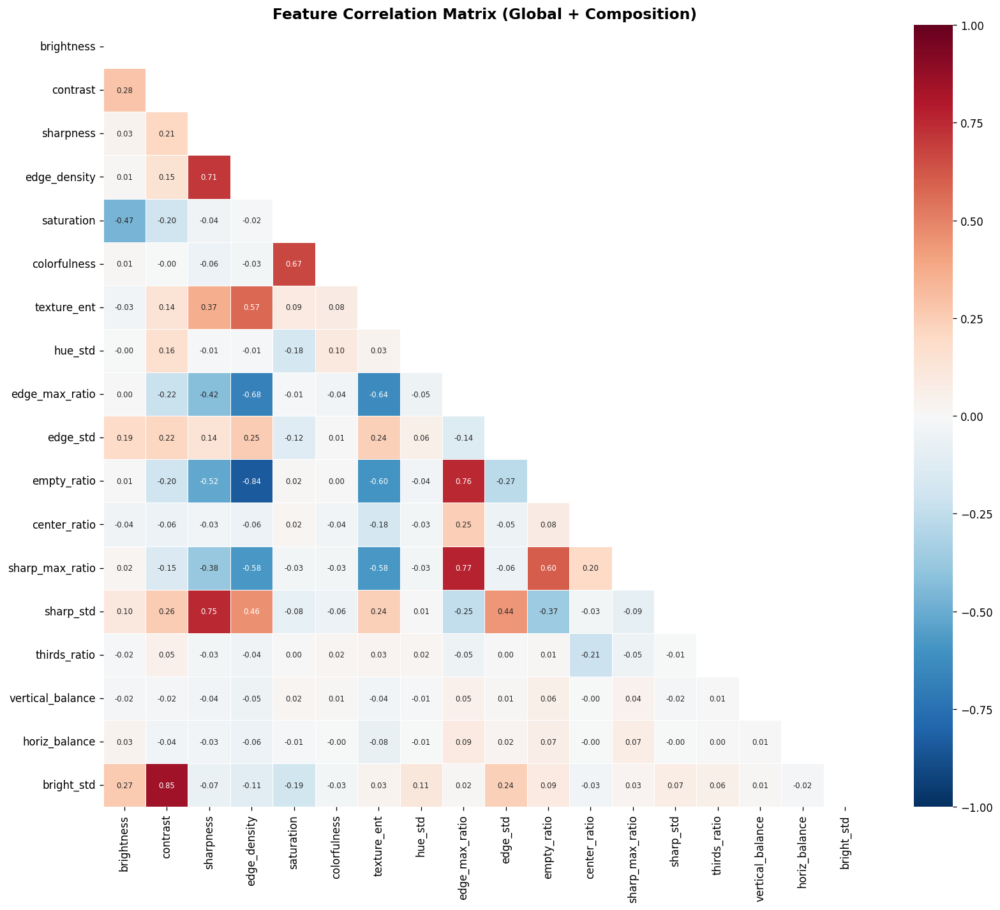

In [24]:
# ── Correlation heatmap ────────────────────────────────────────────────────────
corr_feats = [f for f in (GLOBAL_FEATS + COMP_FEATS) if f in df.columns]
corr_matrix = df[corr_feats].corr()

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, ax=ax, annot_kws={'size': 7})
ax.set_title('Feature Correlation Matrix (Global + Composition)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(REPORT_DIR / 'correlation_matrix.png', bbox_inches='tight')
plt.show()

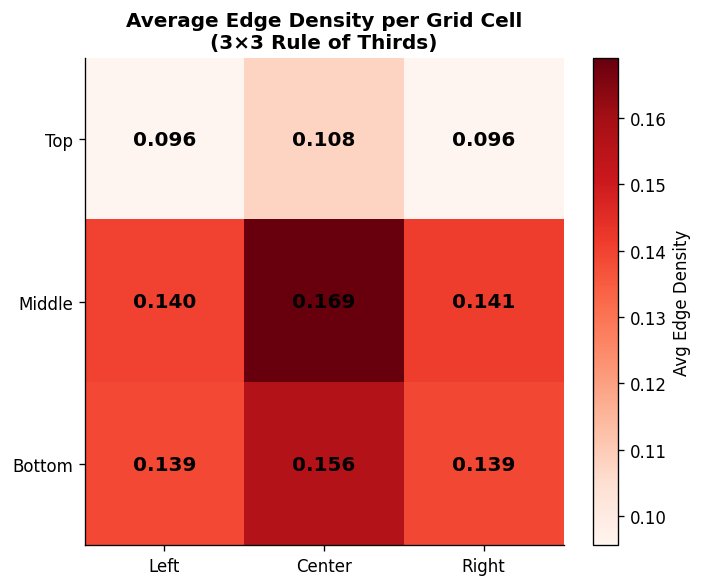

In [25]:
# ── Grid edge heatmap — average structure across all photos ───────────────────
edge_grid_cols = [f'edge_{i}' for i in range(1, 10) if f'edge_{i}' in df.columns]
if len(edge_grid_cols) == 9:
    avg_edges = df[edge_grid_cols].mean().values.reshape(3, 3)

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(avg_edges, cmap='Reds', aspect='auto')
    plt.colorbar(im, ax=ax, label='Avg Edge Density')

    for r in range(3):
        for c in range(3):
            ax.text(c, r, f'{avg_edges[r,c]:.3f}', ha='center', va='center',
                    color='black', fontsize=12, fontweight='bold')

    ax.set_xticks([0,1,2]); ax.set_yticks([0,1,2])
    ax.set_xticklabels(['Left','Center','Right'])
    ax.set_yticklabels(['Top','Middle','Bottom'])
    ax.set_title('Average Edge Density per Grid Cell\n(3×3 Rule of Thirds)', fontweight='bold')
    plt.tight_layout()
    plt.savefig(REPORT_DIR / 'grid_edge_heatmap.png', bbox_inches='tight')
    plt.show()

---
## ⚙️ 6. Preprocessing

In [26]:
# ── Drop NaN rows, cap outliers, scale ────────────────────────────────────────
X_raw = df[ALL_FEATS].copy()
X_raw = X_raw.replace([np.inf, -np.inf], np.nan)

nan_before = X_raw.isna().sum().sum()
X_raw = X_raw.dropna()
df_clean = df.loc[X_raw.index].copy()

print(f'Rows before NaN drop : {len(df):,}')
print(f'NaN cells removed    : {nan_before:,}')
print(f'Rows after NaN drop  : {len(X_raw):,}')

# Robust scaler — less sensitive to outliers
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_raw)
X_scaled_df = pd.DataFrame(X_scaled, columns=ALL_FEATS, index=X_raw.index)

joblib.dump(scaler, MODEL_DIR / 'robust_scaler.pkl')
print(f'\n✅ Scaled shape: {X_scaled.shape}')
print('💾 Scaler saved.')

Rows before NaN drop : 24,997
NaN cells removed    : 35
Rows after NaN drop  : 24,962

✅ Scaled shape: (24962, 45)
💾 Scaler saved.


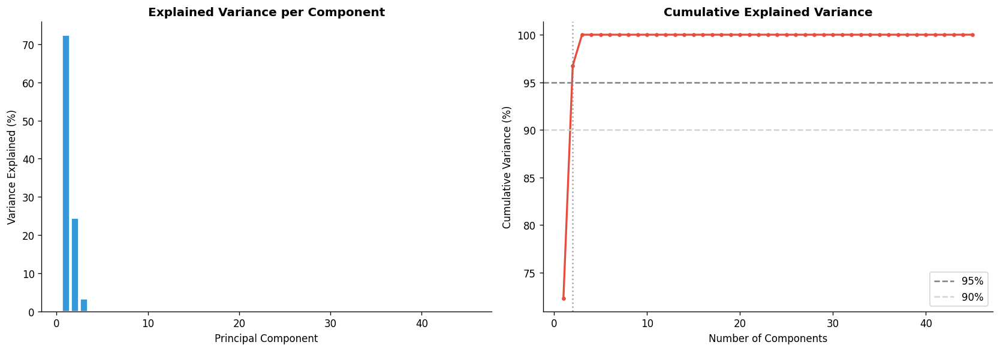

Components for 90% variance: 2
Components for 95% variance: 2

✅ PCA output shape: (24962, 2)


In [27]:
# ── PCA — dimensionality analysis ─────────────────────────────────────────────
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

cumvar = np.cumsum(pca_full.explained_variance_ratio_) * 100
n95 = int(np.searchsorted(cumvar, 95)) + 1
n90 = int(np.searchsorted(cumvar, 90)) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, len(pca_full.explained_variance_ratio_)+1),
            pca_full.explained_variance_ratio_*100,
            color='#3498DB', edgecolor='white')
axes[0].set_title('Explained Variance per Component', fontweight='bold')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Variance Explained (%)')

axes[1].plot(range(1, len(cumvar)+1), cumvar, marker='o', markersize=3,
             color='#E74C3C', linewidth=2)
axes[1].axhline(95, color='gray', linestyle='--', label='95%')
axes[1].axhline(90, color='lightgray', linestyle='--', label='90%')
axes[1].axvline(n95, color='gray', linestyle=':', alpha=0.7)
axes[1].set_title('Cumulative Explained Variance', fontweight='bold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].legend()

plt.tight_layout()
plt.savefig(REPORT_DIR / 'pca_variance.png', bbox_inches='tight')
plt.show()

print(f'Components for 90% variance: {n90}')
print(f'Components for 95% variance: {n95}')

# Use n95 components for clustering
pca = PCA(n_components=min(n95, 20), random_state=42)
X_pca = pca.fit_transform(X_scaled)
joblib.dump(pca, MODEL_DIR / 'pca.pkl')
print(f'\n✅ PCA output shape: {X_pca.shape}')

---
## 🔍 7. Clustering
### 7.1 Optimal K — Elbow + Silhouette

Finding optimal K:   0%|          | 0/10 [00:00<?, ?it/s]

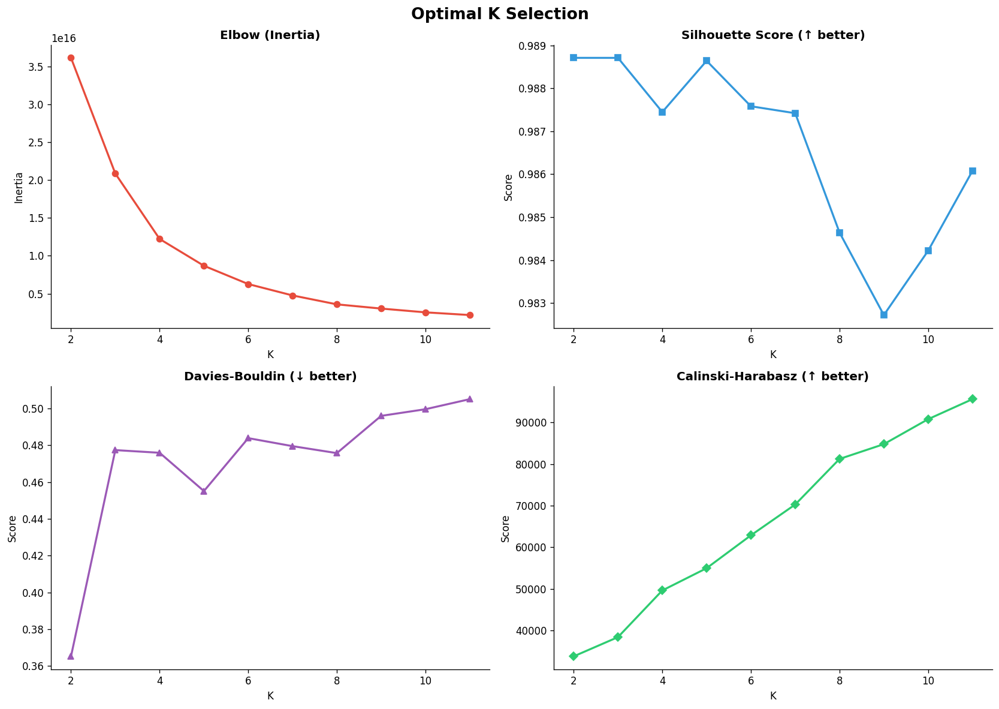

Best K by Silhouette     : 2
Best K by Davies-Bouldin : 2
Best K by Elbow (kneed)  : 4

→ Using K = 2


In [28]:
# ── Elbow method + Silhouette over k ──────────────────────────────────────────
K_RANGE = range(2, 12)

inertias   = []
sil_scores = []
db_scores  = []
ch_scores  = []

for k in tqdm(K_RANGE, desc='Finding optimal K'):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, labels, sample_size=min(5000, len(X_pca))))
    db_scores.append(davies_bouldin_score(X_pca, labels))
    ch_scores.append(calinski_harabasz_score(X_pca, labels))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Optimal K Selection', fontsize=16, fontweight='bold')

ks = list(K_RANGE)

axes[0,0].plot(ks, inertias, 'o-', color='#E74C3C', linewidth=2)
axes[0,0].set_title('Elbow (Inertia)', fontweight='bold')
axes[0,0].set_xlabel('K'); axes[0,0].set_ylabel('Inertia')

axes[0,1].plot(ks, sil_scores, 's-', color='#3498DB', linewidth=2)
axes[0,1].set_title('Silhouette Score (↑ better)', fontweight='bold')
axes[0,1].set_xlabel('K'); axes[0,1].set_ylabel('Score')

axes[1,0].plot(ks, db_scores, '^-', color='#9B59B6', linewidth=2)
axes[1,0].set_title('Davies-Bouldin (↓ better)', fontweight='bold')
axes[1,0].set_xlabel('K'); axes[1,0].set_ylabel('Score')

axes[1,1].plot(ks, ch_scores, 'D-', color='#2ECC71', linewidth=2)
axes[1,1].set_title('Calinski-Harabasz (↑ better)', fontweight='bold')
axes[1,1].set_xlabel('K'); axes[1,1].set_ylabel('Score')

plt.tight_layout()
plt.savefig(REPORT_DIR / 'optimal_k.png', bbox_inches='tight')
plt.show()

best_k_sil = ks[np.argmax(sil_scores)]
best_k_db  = ks[np.argmin(db_scores)]
print(f'Best K by Silhouette     : {best_k_sil}')
print(f'Best K by Davies-Bouldin : {best_k_db}')

if KNEED_AVAILABLE:
    kl = KneeLocator(ks, inertias, curve='convex', direction='decreasing')
    print(f'Best K by Elbow (kneed)  : {kl.knee}')

BEST_K = best_k_sil
print(f'\n→ Using K = {BEST_K}')

### 7.2 K-Means

In [29]:
print(f'Training K-Means (K={BEST_K}) …')
kmeans = KMeans(n_clusters=BEST_K, n_init=20, max_iter=500, random_state=42)
km_labels = kmeans.fit_predict(X_pca)

df_clean['cluster_kmeans'] = km_labels

km_sil = silhouette_score(X_pca, km_labels, sample_size=min(5000, len(X_pca)))
km_db  = davies_bouldin_score(X_pca, km_labels)
km_ch  = calinski_harabasz_score(X_pca, km_labels)

print(f'K-Means Results:')
print(f'  Silhouette       : {km_sil:.4f}')
print(f'  Davies-Bouldin   : {km_db:.4f}')
print(f'  Calinski-Harabasz: {km_ch:.1f}')

joblib.dump(kmeans, MODEL_DIR / 'kmeans.pkl')
print('💾 KMeans saved.')

Training K-Means (K=2) …
K-Means Results:
  Silhouette       : 0.9926
  Davies-Bouldin   : 0.3652
  Calinski-Harabasz: 33833.3
💾 KMeans saved.


### 7.3 Gaussian Mixture Model

In [30]:
print(f'Training GMM (K={BEST_K}) …')

# Try different covariance types and pick best BIC
cov_types = ['full', 'tied', 'diag', 'spherical']
best_bic  = np.inf
best_gmm  = None
best_cov  = None

for cov in tqdm(cov_types, desc='GMM covariance search'):
    try:
        gmm = GaussianMixture(n_components=BEST_K, covariance_type=cov,
                              max_iter=200, random_state=42)
        gmm.fit(X_pca)
        bic = gmm.bic(X_pca)
        print(f'  {cov:10s} BIC = {bic:.1f}')
        if bic < best_bic:
            best_bic = bic
            best_gmm = gmm
            best_cov = cov
    except Exception as e:
        print(f'  {cov}: failed ({e})')

gmm_labels = best_gmm.predict(X_pca)
gmm_proba  = best_gmm.predict_proba(X_pca)
df_clean['cluster_gmm'] = gmm_labels

gmm_sil = silhouette_score(X_pca, gmm_labels, sample_size=min(5000, len(X_pca)))
gmm_db  = davies_bouldin_score(X_pca, gmm_labels)

print(f'\nBest GMM covariance: {best_cov} (BIC={best_bic:.1f})')
print(f'GMM Results:')
print(f'  Silhouette     : {gmm_sil:.4f}')
print(f'  Davies-Bouldin : {gmm_db:.4f}')

joblib.dump(best_gmm, MODEL_DIR / 'gmm.pkl')
print('💾 GMM saved.')

Training GMM (K=2) …


GMM covariance search:   0%|          | 0/4 [00:00<?, ?it/s]

  full       BIC = 269723.7
  tied       BIC = 1505421.3
  diag       BIC = 269717.3
  spherical  BIC = 270952.9

Best GMM covariance: diag (BIC=269717.3)
GMM Results:
  Silhouette     : 0.8974
  Davies-Bouldin : 1.8158
💾 GMM saved.


### 7.4 DBSCAN

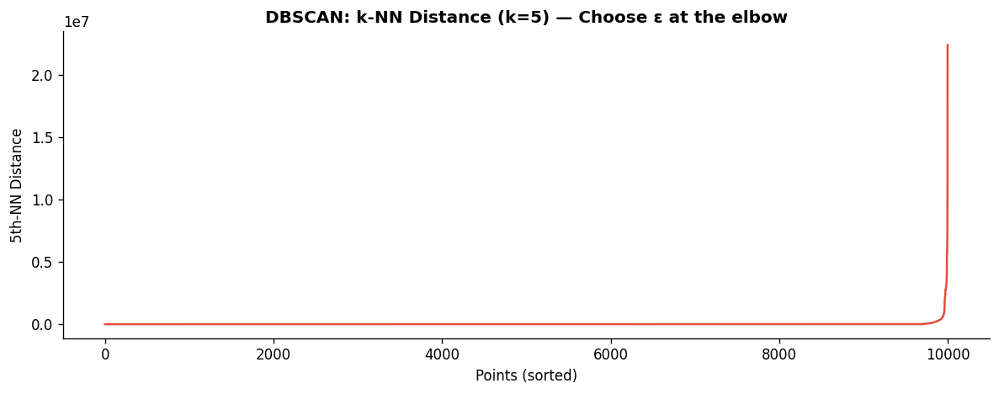

Auto-selected ε = 0.2320


In [31]:
# ── DBSCAN epsilon selection via k-NN distance plot ───────────────────────────
from sklearn.neighbors import NearestNeighbors

# Sample for speed if dataset is large
sample_size = min(10000, len(X_pca))
idx_sample  = np.random.choice(len(X_pca), sample_size, replace=False)
X_sample    = X_pca[idx_sample]

nbrs = NearestNeighbors(n_neighbors=5).fit(X_sample)
dists, _ = nbrs.kneighbors(X_sample)
knn_dists = np.sort(dists[:, -1])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(knn_dists, color='#E74C3C', linewidth=1.5)
ax.set_title('DBSCAN: k-NN Distance (k=5) — Choose ε at the elbow', fontweight='bold')
ax.set_xlabel('Points (sorted)')
ax.set_ylabel('5th-NN Distance')
plt.tight_layout()
plt.savefig(REPORT_DIR / 'dbscan_eps_selection.png', bbox_inches='tight')
plt.show()

# Auto-select eps at 90th percentile of knn distances
EPS_AUTO = float(np.percentile(knn_dists, 90))
print(f'Auto-selected ε = {EPS_AUTO:.4f}')

In [32]:
print(f'Training DBSCAN (eps={EPS_AUTO:.4f}, min_samples=5) …')
dbscan = DBSCAN(eps=EPS_AUTO, min_samples=5, n_jobs=-1)
db_labels = dbscan.fit_predict(X_pca)
df_clean['cluster_dbscan'] = db_labels

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise_db    = (db_labels == -1).sum()

print(f'DBSCAN Results:')
print(f'  Clusters found : {n_clusters_db}')
print(f'  Noise points   : {n_noise_db:,} ({n_noise_db/len(db_labels)*100:.1f}%)')

if n_clusters_db >= 2:
    mask_core = db_labels != -1
    db_sil = silhouette_score(X_pca[mask_core], db_labels[mask_core],
                              sample_size=min(5000, mask_core.sum()))
    print(f'  Silhouette (core only): {db_sil:.4f}')

joblib.dump(dbscan, MODEL_DIR / 'dbscan.pkl')
print('💾 DBSCAN saved.')

Training DBSCAN (eps=0.2320, min_samples=5) …
DBSCAN Results:
  Clusters found : 27
  Noise points   : 1,711 (6.9%)
  Silhouette (core only): 0.4657
💾 DBSCAN saved.


---
## 📈 8. Model Evaluation & Comparison

In [33]:
# ── Summary evaluation table ───────────────────────────────────────────────────
eval_rows = []

# KMeans
eval_rows.append({
    'Algorithm': 'K-Means',
    'N Clusters': BEST_K,
    'Silhouette': km_sil,
    'Davies-Bouldin': km_db,
    'Calinski-Harabasz': km_ch,
    'Noise Points': 0,
})

# GMM
eval_rows.append({
    'Algorithm': 'GMM',
    'N Clusters': BEST_K,
    'Silhouette': gmm_sil,
    'Davies-Bouldin': gmm_db,
    'Calinski-Harabasz': calinski_harabasz_score(X_pca, gmm_labels),
    'Noise Points': 0,
})

# DBSCAN
if n_clusters_db >= 2:
    eval_rows.append({
        'Algorithm': 'DBSCAN',
        'N Clusters': n_clusters_db,
        'Silhouette': db_sil,
        'Davies-Bouldin': davies_bouldin_score(X_pca[mask_core], db_labels[mask_core]),
        'Calinski-Harabasz': calinski_harabasz_score(X_pca[mask_core], db_labels[mask_core]),
        'Noise Points': n_noise_db,
    })

eval_df = pd.DataFrame(eval_rows).set_index('Algorithm')
eval_df = eval_df.round(4)
print('=== CLUSTERING EVALUATION SUMMARY ===')
print(eval_df.to_string())
eval_df.to_csv(REPORT_DIR / 'cluster_evaluation.csv')

=== CLUSTERING EVALUATION SUMMARY ===
           N Clusters  Silhouette  Davies-Bouldin  Calinski-Harabasz  Noise Points
Algorithm                                                                         
K-Means             2      0.9926          0.3652         33833.2607             0
GMM                 2      0.8974          1.8158          2441.9505             0
DBSCAN             27      0.4657          0.4085           341.6389          1711


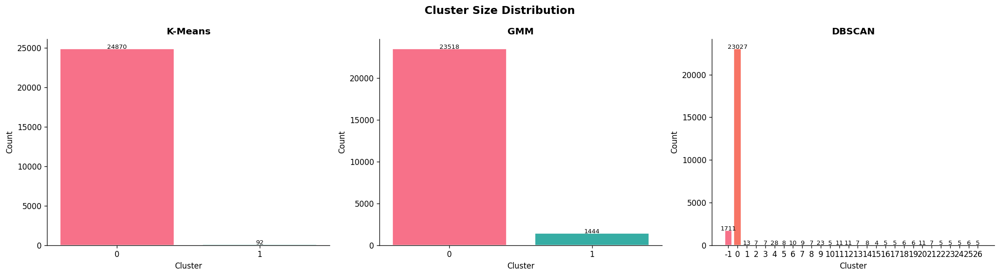

In [34]:
# ── Cluster size distributions ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Cluster Size Distribution', fontsize=14, fontweight='bold')

for ax, col, title in zip(axes,
    ['cluster_kmeans', 'cluster_gmm', 'cluster_dbscan'],
    ['K-Means', 'GMM', 'DBSCAN']):
    if col in df_clean.columns:
        counts = df_clean[col].value_counts().sort_index()
        ax.bar(counts.index.astype(str), counts.values,
               color=sns.color_palette('husl', len(counts)), edgecolor='white')
        ax.set_title(title, fontweight='bold')
        ax.set_xlabel('Cluster')
        ax.set_ylabel('Count')
        for i, (idx, val) in enumerate(counts.items()):
            ax.text(i, val + 10, str(val), ha='center', fontsize=8)

plt.tight_layout()
plt.savefig(REPORT_DIR / 'cluster_sizes.png', bbox_inches='tight')
plt.show()

---
## 🗺️ 9. Visualization — t-SNE & UMAP

Running t-SNE (this may take a few minutes) …


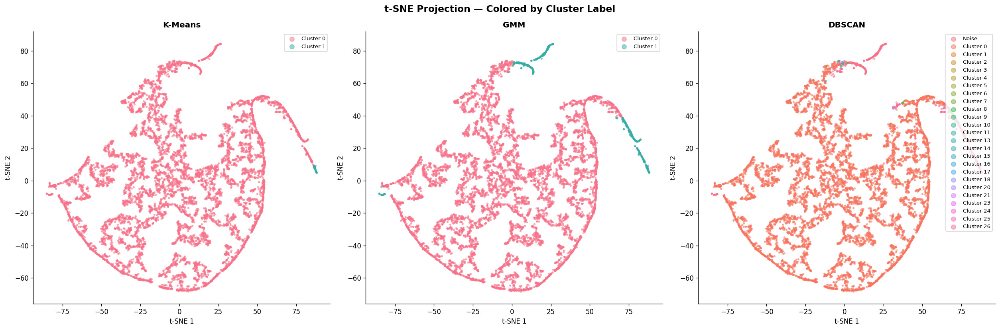

In [36]:
# ── t-SNE on PCA output ────────────────────────────────────────────────────────
print('Running t-SNE (this may take a few minutes) …')
tsne_sample = min(8000, len(X_pca))
tsne_idx    = np.random.choice(len(X_pca), tsne_sample, replace=False)
X_tsne_input= X_pca[tsne_idx]

tsne = TSNE(n_components=2, perplexity=40, random_state=42, n_jobs=-1)
X_tsne = tsne.fit_transform(X_tsne_input)

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
fig.suptitle('t-SNE Projection — Colored by Cluster Label', fontsize=14, fontweight='bold')

for ax, col, title in zip(axes,
    ['cluster_kmeans', 'cluster_gmm', 'cluster_dbscan'],
    ['K-Means', 'GMM', 'DBSCAN']):
    if col in df_clean.columns:
        labels_sub = df_clean[col].values[tsne_idx]
        unique_labels = sorted(set(labels_sub))
        palette = sns.color_palette('husl', len(unique_labels))
        for lbl, color in zip(unique_labels, palette):
            mask = labels_sub == lbl
            label_name = f'Cluster {lbl}' if lbl != -1 else 'Noise'
            ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
                       c=[color], label=label_name, s=5, alpha=0.5)
        ax.set_title(title, fontweight='bold')
        ax.legend(markerscale=3, fontsize=8)
        ax.set_xlabel('t-SNE 1')
        ax.set_ylabel('t-SNE 2')

plt.tight_layout()
plt.savefig(REPORT_DIR / 'tsne_clusters.png', bbox_inches='tight')
plt.show()

Running UMAP …


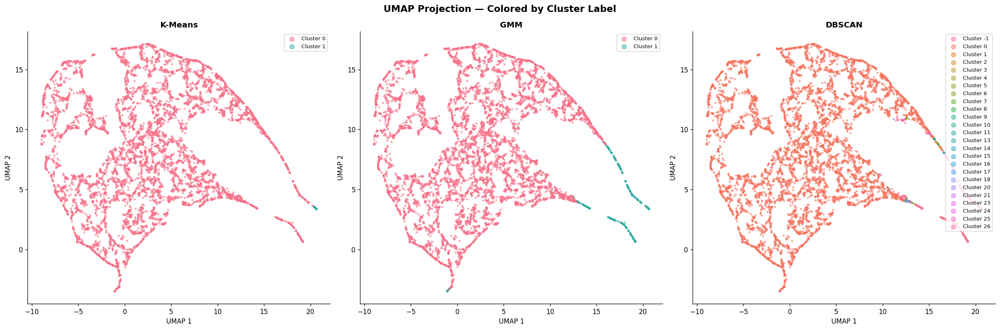

In [37]:
if UMAP_AVAILABLE:
    print('Running UMAP …')
    reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
    X_umap  = reducer.fit_transform(X_pca[tsne_idx])

    fig, axes = plt.subplots(1, 3, figsize=(21, 7))
    fig.suptitle('UMAP Projection — Colored by Cluster Label', fontsize=14, fontweight='bold')

    for ax, col, title in zip(axes,
        ['cluster_kmeans', 'cluster_gmm', 'cluster_dbscan'],
        ['K-Means', 'GMM', 'DBSCAN']):
        if col in df_clean.columns:
            labels_sub = df_clean[col].values[tsne_idx]
            unique_labels = sorted(set(labels_sub))
            palette = sns.color_palette('husl', len(unique_labels))
            for lbl, color in zip(unique_labels, palette):
                mask = labels_sub == lbl
                ax.scatter(X_umap[mask, 0], X_umap[mask, 1],
                           c=[color], label=f'Cluster {lbl}', s=5, alpha=0.5)
            ax.set_title(title, fontweight='bold')
            ax.legend(markerscale=3, fontsize=8)
            ax.set_xlabel('UMAP 1')
            ax.set_ylabel('UMAP 2')

    plt.tight_layout()
    plt.savefig(REPORT_DIR / 'umap_clusters.png', bbox_inches='tight')
    plt.show()
else:
    print('UMAP not available — skipping.')

---
## 🏷️ 10. Cluster Interpretation & Style Detection

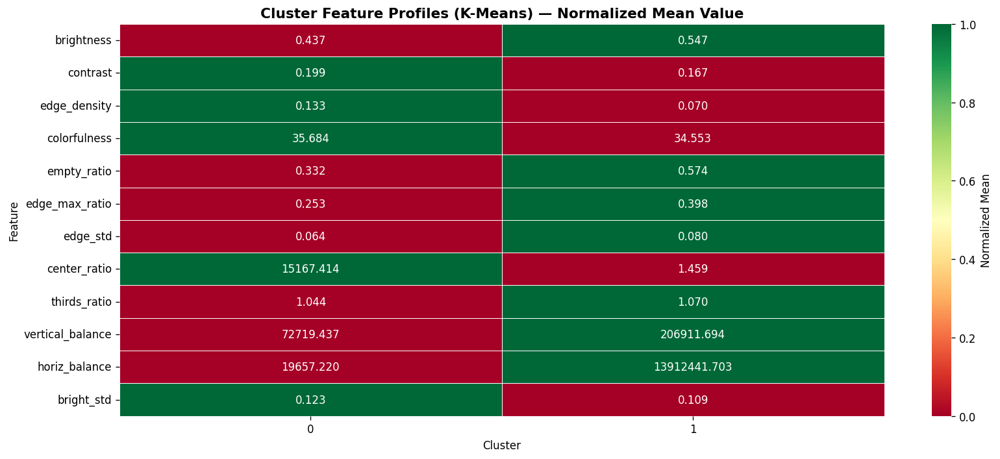

                brightness  contrast  edge_density  colorfulness  empty_ratio  edge_max_ratio  edge_std  center_ratio  thirds_ratio  vertical_balance  horiz_balance  bright_std
cluster_kmeans                                                                                                                                                                  
0                 0.436757  0.199047      0.133131     35.683514     0.331805        0.253258  0.063853  15167.413567      1.043793      72719.436544   1.965722e+04    0.122909
1                 0.547233  0.167131      0.070240     34.552647     0.573671        0.398330  0.079780      1.459485      1.069598     206911.693582   1.391244e+07    0.108733


In [38]:
# ── Cluster feature profiles (K-Means) ────────────────────────────────────────
KEY_FEATS = ['brightness','contrast','edge_density','colorfulness',
             'empty_ratio','edge_max_ratio','edge_std','center_ratio',
             'thirds_ratio','vertical_balance','horiz_balance','bright_std']
KEY_FEATS = [f for f in KEY_FEATS if f in df_clean.columns]

df_clean_feats = df_clean.copy()
for feat in ALL_FEATS:
    if feat in df_clean.columns:
        continue
    if feat in X_raw.columns:
        df_clean_feats[feat] = X_raw[feat].values

# Compute per-cluster means for key features
cluster_profile = df_clean_feats.groupby('cluster_kmeans')[KEY_FEATS].mean()

# Normalize for radar/heatmap
cluster_profile_norm = (cluster_profile - cluster_profile.min()) / \
                       (cluster_profile.max() - cluster_profile.min() + 1e-8)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(cluster_profile_norm.T, annot=cluster_profile.T.round(3),
            fmt='.3f', cmap='RdYlGn', center=0.5,
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Normalized Mean'})
ax.set_title('Cluster Feature Profiles (K-Means) — Normalized Mean Value',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Cluster')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.savefig(REPORT_DIR / 'cluster_profiles.png', bbox_inches='tight')
plt.show()

print(cluster_profile.to_string())

Minimalist score threshold (75th pct): 0.5483
Minimalist photos : 6,241
Non-minimalist    : 18,721


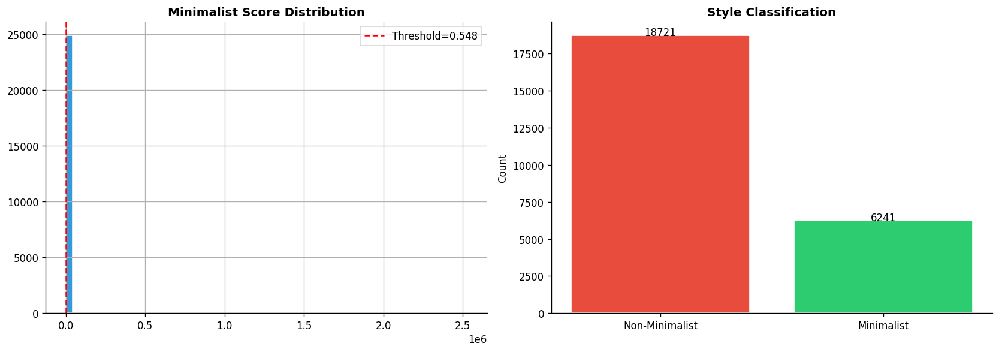

In [39]:
# ── Minimalist score ───────────────────────────────────────────────────────────
# Combining: high empty_ratio + high edge_max_ratio + high edge_std
# → low brightness_std (uniform background)
def compute_minimalist_score(row) -> float:
    er  = row.get('empty_ratio',     0.0)
    emr = row.get('edge_max_ratio',  0.0)
    es  = row.get('edge_std',        0.0)
    cr  = row.get('center_ratio',    0.0)
    # Weighted score — tune weights based on domain knowledge
    score = (0.35 * er) + (0.30 * emr) + (0.20 * es) + (0.15 * cr)
    return float(score)

if 'empty_ratio' in df_clean.columns:
    df_clean['minimalist_score'] = df_clean.apply(compute_minimalist_score, axis=1)

    # Threshold at 75th percentile → label top quartile as minimalist
    thresh = df_clean['minimalist_score'].quantile(0.75)
    df_clean['is_minimalist'] = (df_clean['minimalist_score'] >= thresh).astype(int)

    print(f'Minimalist score threshold (75th pct): {thresh:.4f}')
    print(f'Minimalist photos : {df_clean["is_minimalist"].sum():,}')
    print(f'Non-minimalist    : {(df_clean["is_minimalist"] == 0).sum():,}')

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    df_clean['minimalist_score'].hist(bins=60, ax=axes[0], color='#3498DB', edgecolor='white')
    axes[0].axvline(thresh, color='red', linestyle='--', label=f'Threshold={thresh:.3f}')
    axes[0].set_title('Minimalist Score Distribution', fontweight='bold')
    axes[0].legend()

    counts = df_clean['is_minimalist'].value_counts().sort_index()
    axes[1].bar(['Non-Minimalist', 'Minimalist'], counts.values,
                color=['#E74C3C', '#2ECC71'], edgecolor='white')
    axes[1].set_title('Style Classification', fontweight='bold')
    axes[1].set_ylabel('Count')
    for i, v in enumerate(counts.values):
        axes[1].text(i, v + 10, str(v), ha='center')

    plt.tight_layout()
    plt.savefig(REPORT_DIR / 'minimalist_distribution.png', bbox_inches='tight')
    plt.show()

In [40]:
# ── Auto-label clusters ────────────────────────────────────────────────────────
STYLE_LABELS = {}

if 'minimalist_score' in cluster_profile.columns:
    style_col = 'minimalist_score'
elif 'empty_ratio' in cluster_profile.columns:
    style_col = 'empty_ratio'
else:
    style_col = None

if style_col:
    scores = cluster_profile[style_col].sort_values(ascending=False)
    top_cluster    = int(scores.index[0])
    bottom_cluster = int(scores.index[-1])

    for cid in cluster_profile.index:
        cid = int(cid)
        if cid == top_cluster:
            STYLE_LABELS[cid] = 'Minimalist'
        elif cid == bottom_cluster:
            STYLE_LABELS[cid] = 'Busy/Complex'
        else:
            STYLE_LABELS[cid] = f'Style {cid}'

    df_clean['style_label'] = df_clean['cluster_kmeans'].map(STYLE_LABELS)
    print('Cluster → Style label mapping:')
    for cid, label in STYLE_LABELS.items():
        print(f'  Cluster {cid}: {label}')

Cluster → Style label mapping:
  Cluster 0: Busy/Complex
  Cluster 1: Minimalist


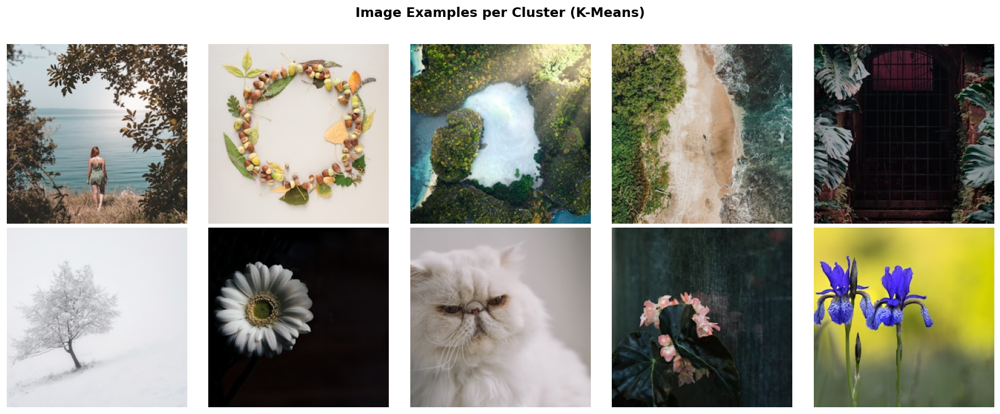

In [41]:
# ── Show image examples per cluster ───────────────────────────────────────────
N_EXAMPLES = 5

unique_clusters = sorted(df_clean['cluster_kmeans'].unique())
fig, axes = plt.subplots(len(unique_clusters), N_EXAMPLES,
                          figsize=(N_EXAMPLES * 3, len(unique_clusters) * 3))
fig.suptitle('Image Examples per Cluster (K-Means)', fontsize=14,
             fontweight='bold', y=1.01)

if len(unique_clusters) == 1:
    axes = [axes]

for row_ax, cid in zip(axes, unique_clusters):
    cluster_rows = df_clean[df_clean['cluster_kmeans'] == cid]
    label_str = STYLE_LABELS.get(cid, f'Cluster {cid}')

    # For minimalist cluster, sort by minimalist score desc
    if 'minimalist_score' in cluster_rows.columns:
        cluster_rows = cluster_rows.sort_values('minimalist_score',
            ascending=(label_str != 'Minimalist'))

    sample = cluster_rows.head(N_EXAMPLES)

    for col_idx, (_, r) in enumerate(sample.iterrows()):
        ax = row_ax[col_idx] if hasattr(row_ax, '__len__') else row_ax
        try:
            img = Image.open(r['path']).convert('RGB').resize((256, 256))
            ax.imshow(img)
        except Exception:
            ax.text(0.5, 0.5, 'Error', ha='center', va='center',
                    transform=ax.transAxes)
        ax.axis('off')
        if col_idx == 0:
            ax.set_ylabel(label_str, fontsize=10, fontweight='bold', rotation=90,
                         labelpad=5)
            ax.yaxis.set_label_position('left')
            ax.yaxis.label.set_visible(True)

plt.tight_layout()
plt.savefig(REPORT_DIR / 'cluster_image_examples.png', bbox_inches='tight')
plt.show()

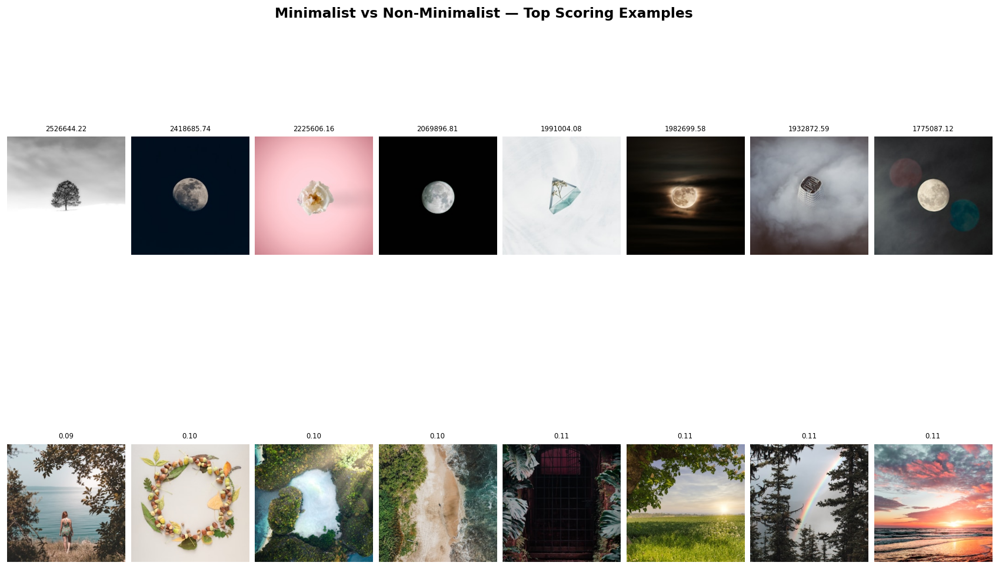

In [42]:
# ── Visual deep-dive: Minimalist vs Busy side-by-side ─────────────────────────
if 'is_minimalist' in df_clean.columns:
    mini_sample = df_clean[df_clean['is_minimalist'] == 1].nlargest(8, 'minimalist_score')
    busy_sample = df_clean[df_clean['is_minimalist'] == 0].nsmallest(8, 'minimalist_score')

    fig = plt.figure(figsize=(18, 10))
    fig.suptitle('Minimalist vs Non-Minimalist — Top Scoring Examples',
                 fontsize=14, fontweight='bold')

    gs = gridspec.GridSpec(2, 8, figure=fig, hspace=0.3, wspace=0.05)

    for col_idx, (_, row) in enumerate(mini_sample.iterrows()):
        ax = fig.add_subplot(gs[0, col_idx])
        try:
            img = Image.open(row['path']).convert('RGB').resize((256, 256))
            ax.imshow(img)
        except:
            pass
        score = row.get('minimalist_score', 0)
        ax.set_title(f'{score:.2f}', fontsize=7)
        ax.axis('off')
        if col_idx == 0:
            ax.set_ylabel('✅ Minimalist', fontsize=10, fontweight='bold')
            ax.yaxis.label.set_visible(True)

    for col_idx, (_, row) in enumerate(busy_sample.iterrows()):
        ax = fig.add_subplot(gs[1, col_idx])
        try:
            img = Image.open(row['path']).convert('RGB').resize((256, 256))
            ax.imshow(img)
        except:
            pass
        score = row.get('minimalist_score', 0)
        ax.set_title(f'{score:.2f}', fontsize=7)
        ax.axis('off')
        if col_idx == 0:
            ax.set_ylabel('❌ Non-Minimalist', fontsize=10, fontweight='bold')
            ax.yaxis.label.set_visible(True)

    plt.savefig(REPORT_DIR / 'minimalist_vs_busy.png', bbox_inches='tight')
    plt.show()

---
## 💾 11. Save Models, Features & Results

In [43]:
# ── Save all artifacts ─────────────────────────────────────────────────────────

# 1. Full labeled dataframe
df_clean.to_parquet(FEATURE_DIR / 'labeled_photos.parquet', index=False)
df_clean.to_csv(REPORT_DIR / 'labeled_photos.csv', index=False)
print('💾 Labeled dataset saved.')

# 2. Models already saved above; save a combined config
config = {
    'img_size':        list(IMG_SIZE),
    'grid_size':       GRID_SIZE,
    'best_k':          int(BEST_K),
    'n_pca_components':int(pca.n_components_),
    'all_features':    ALL_FEATS,
    'low_edge_thresh': LOW_EDGE_THRESH,
    'style_labels':    {str(k): v for k, v in STYLE_LABELS.items()},
    'created_at':      pd.Timestamp.now().isoformat(),
}
with open(MODEL_DIR / 'config.json', 'w') as f:
    json.dump(config, f, indent=2)
print('💾 Config saved.')

# 3. Evaluation results
eval_df.to_csv(REPORT_DIR / 'cluster_evaluation.csv')
print('💾 Evaluation CSV saved.')

print()
print('=== ALL SAVED FILES ===')
for path in sorted(MODEL_DIR.glob('*')) + sorted(REPORT_DIR.glob('*')):
    size_kb = path.stat().st_size / 1024
    print(f'  {path.relative_to(BASE_DIR)}  ({size_kb:.1f} KB)')

💾 Labeled dataset saved.
💾 Config saved.
💾 Evaluation CSV saved.

=== ALL SAVED FILES ===
  models/config.json  (1.0 KB)
  models/dbscan.pkl  (736.1 KB)
  models/gmm.pkl  (1.3 KB)
  models/kmeans.pkl  (98.2 KB)
  models/pca.pkl  (2.0 KB)
  models/robust_scaler.pkl  (2.0 KB)
  reports/cluster_evaluation.csv  (0.2 KB)
  reports/cluster_image_examples.png  (1326.2 KB)
  reports/cluster_profiles.png  (79.0 KB)
  reports/cluster_sizes.png  (40.7 KB)
  reports/correlation_matrix.png  (159.0 KB)
  reports/dbscan_eps_selection.png  (24.3 KB)
  reports/eda_aspect_ratio.png  (42.1 KB)
  reports/eda_keywords.png  (61.9 KB)
  reports/eda_overview.png  (83.6 KB)
  reports/feature_distributions_composition.png  (81.7 KB)
  reports/feature_distributions_global.png  (71.1 KB)
  reports/grid_edge_heatmap.png  (36.0 KB)
  reports/labeled_photos.csv  (24512.6 KB)
  reports/minimalist_distribution.png  (38.3 KB)
  reports/minimalist_vs_busy.png  (859.2 KB)
  reports/optimal_k.png  (119.1 KB)
  reports/pca

---
## 🔮 12. Inference Pipeline (Core ML Ready)

Demonstrates how to classify a **new, unseen image** using the trained pipeline.

bVOKzG9zSek: {'cluster': 0, 'style': 'Busy/Complex', 'minimalist_score': 0.3696, 'is_minimalist': np.False_, 'features': {'empty_ratio': 0.5556, 'edge_max_ratio': 0.3099, 'brightness': 0.4471, 'colorfulness': 58.3554}}
4-Yw22oNZmE: {'cluster': 0, 'style': 'Busy/Complex', 'minimalist_score': 0.2842, 'is_minimalist': np.False_, 'features': {'empty_ratio': 0.0, 'edge_max_ratio': 0.1773, 'brightness': 0.4204, 'colorfulness': 13.2577}}
NuXIbzxI3pU: {'cluster': 0, 'style': 'Busy/Complex', 'minimalist_score': 0.1959, 'is_minimalist': np.False_, 'features': {'empty_ratio': 0.0, 'edge_max_ratio': 0.1333, 'brightness': 0.1713, 'colorfulness': 35.6615}}


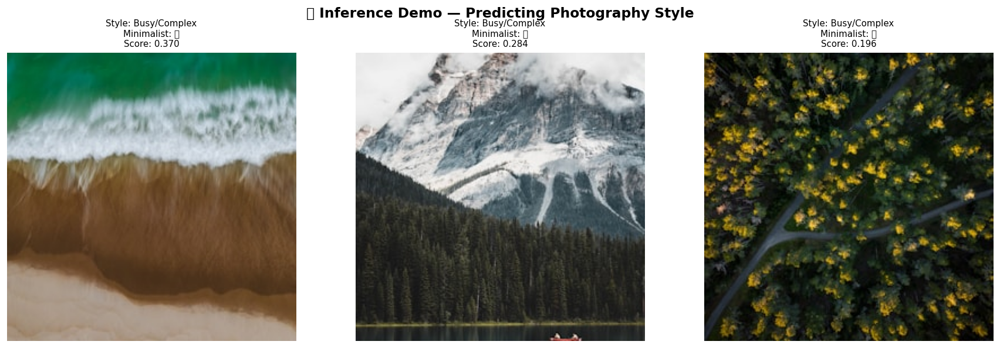

In [44]:
def predict_style(image_path: str,
                  scaler, pca, kmeans,
                  style_labels: dict,
                  all_feats: list) -> dict:
    """
    End-to-end inference for a single image.
    Returns cluster, style label, and minimalist score.
    """
    # Extract features
    feats = extract_all_features(image_path)
    if feats is None:
        return {'error': 'Feature extraction failed'}

    # Build ordered feature vector
    feat_vec = np.array([feats.get(f, 0.0) for f in all_feats]).reshape(1, -1)

    # Scale → PCA → Cluster
    feat_scaled = scaler.transform(feat_vec)
    feat_pca    = pca.transform(feat_scaled)
    cluster     = int(kmeans.predict(feat_pca)[0])
    style       = style_labels.get(cluster, f'Cluster {cluster}')

    # Minimalist score
    mini_score = compute_minimalist_score(feats)

    return {
        'cluster':           cluster,
        'style':             style,
        'minimalist_score':  round(mini_score, 4),
        'is_minimalist':     mini_score >= df_clean['minimalist_score'].quantile(0.75),
        'features': {
            'empty_ratio':    round(feats.get('empty_ratio', 0), 4),
            'edge_max_ratio': round(feats.get('edge_max_ratio', 0), 4),
            'brightness':     round(feats.get('brightness', 0), 4),
            'colorfulness':   round(feats.get('colorfulness', 0), 4),
        }
    }


# Load saved models for demo
_scaler = joblib.load(MODEL_DIR / 'robust_scaler.pkl')
_pca    = joblib.load(MODEL_DIR / 'pca.pkl')
_kmeans = joblib.load(MODEL_DIR / 'kmeans.pkl')

# Test on 3 random images
test_images = df_clean['path'].dropna().sample(3, random_state=7).tolist()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('🔮 Inference Demo — Predicting Photography Style', fontsize=14, fontweight='bold')

for ax, path in zip(axes, test_images):
    result = predict_style(path, _scaler, _pca, _kmeans, STYLE_LABELS, ALL_FEATS)
    try:
        img = Image.open(path).convert('RGB').resize((256, 256))
        ax.imshow(img)
    except:
        pass

    title = (f"Style: {result.get('style', '?')}\n"
             f"Minimalist: {'✅' if result.get('is_minimalist') else '❌'}\n"
             f"Score: {result.get('minimalist_score', 0):.3f}")
    ax.set_title(title, fontsize=9)
    ax.axis('off')
    print(f'{Path(path).stem}: {result}')

plt.tight_layout()
plt.savefig(REPORT_DIR / 'inference_demo.png', bbox_inches='tight')
plt.show()

---
## 📋 13. Final Summary Report

In [45]:
print('=' * 60)
print('   AESTHETIC PHOTOGRAPHY DETECTION — FINAL REPORT')
print('=' * 60)
print(f'\nDataset')
print(f'  Total photos loaded   : {len(photos):,}')
print(f'  Images downloaded     : {len(photos_valid):,}')
print(f'  Features extracted    : {len(features_df):,}')
print(f'  Feature dimensions    : {len(ALL_FEATS)}')
print()
print(f'Preprocessing')
print(f'  Scaler                : RobustScaler')
print(f'  PCA components        : {pca.n_components_} (covering ~95% variance)')
print()
print(f'Clustering')
print(f'  Optimal K             : {BEST_K}')
print(f'  Best model (silhouette): {eval_df["Silhouette"].idxmax()} ({eval_df["Silhouette"].max():.4f})')
print()
print('  Algorithm   | Silhouette | Davies-Bouldin | Clusters')
print('  ' + '-'*55)
for algo, row in eval_df.iterrows():
    print(f'  {algo:10s}  | {row["Silhouette"]:10.4f} | {row["Davies-Bouldin"]:14.4f} | {row["N Clusters"]}')
print()
if STYLE_LABELS:
    print(f'Style Labels Detected')
    for cid, label in STYLE_LABELS.items():
        n_photos = (df_clean['cluster_kmeans'] == cid).sum()
        print(f'  Cluster {cid} → {label:20s} ({n_photos:,} photos)')
print()
if 'is_minimalist' in df_clean.columns:
    print(f'Minimalist Detection')
    n_mini = df_clean['is_minimalist'].sum()
    print(f'  Minimalist photos     : {n_mini:,} ({n_mini/len(df_clean)*100:.1f}%)')
    print(f'  Non-minimalist        : {len(df_clean)-n_mini:,}')
print()
print('Saved Artifacts')
print(f'  Models dir            : {MODEL_DIR.resolve()}')
print(f'  Reports dir           : {REPORT_DIR.resolve()}')
print(f'  Feature cache         : {FEATURE_CACHE.resolve()}')
print()
print('✅ Pipeline complete — ready for Core ML export!')
print('=' * 60)

   AESTHETIC PHOTOGRAPHY DETECTION — FINAL REPORT

Dataset
  Total photos loaded   : 25,000
  Images downloaded     : 24,997
  Features extracted    : 24,997
  Feature dimensions    : 45

Preprocessing
  Scaler                : RobustScaler
  PCA components        : 2 (covering ~95% variance)

Clustering
  Optimal K             : 2
  Best model (silhouette): K-Means (0.9926)

  Algorithm   | Silhouette | Davies-Bouldin | Clusters
  -------------------------------------------------------
  K-Means     |     0.9926 |         0.3652 | 2.0
  GMM         |     0.8974 |         1.8158 | 2.0
  DBSCAN      |     0.4657 |         0.4085 | 27.0

Style Labels Detected
  Cluster 0 → Busy/Complex         (24,870 photos)
  Cluster 1 → Minimalist           (92 photos)

Minimalist Detection
  Minimalist photos     : 6,241 (25.0%)
  Non-minimalist        : 18,721

Saved Artifacts
  Models dir            : /Users/rafiabhista/Documents/code/apple/c1_tabular/grid_project_2/models
  Reports dir           :

---
## 🍎 14. (Optional) Core ML Export

Export the K-Means + Scaler pipeline to `.mlmodel` for iOS deployment.

In [ ]:
# Install coremltools (macOS / Linux only)
# subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'coremltools', '-q'])

# import coremltools as ct
# from sklearn.pipeline import Pipeline
#
# pipeline = Pipeline([
#     ('scaler', scaler),
#     ('pca',    pca),
#     ('kmeans', kmeans),
# ])
#
# cml_model = ct.converters.sklearn.convert(pipeline, ALL_FEATS, 'cluster_label')
# cml_model.short_description = 'Aesthetic Photography Style Detector'
# cml_model.save(str(MODEL_DIR / 'AestheticStyleDetector.mlmodel'))
# print('✅ Core ML model exported.')

print('⚠️  Core ML export is commented out.')
print('   Uncomment the block above on macOS to generate AestheticStyleDetector.mlmodel')